# Somnolencia al volante en la ruta Golfito–San José
**MA-0321 Cálculo Diferencial e Integral · Proyecto Aplicado 2 · Estudiante C-02 (Fernández Vílchez)**

**Cliente:** empresa de autobuses que prueba una diadema EEG que alerta al chofer cuando empieza a dormirse.

**Pregunta de decisión:** ¿qué umbral del índice de bandas debe usar la diadema para activar la alarma?

**Criterio de éxito:** sensibilidad ≥ 90 % (hoja `Parametros`) con el menor costo por errores; se informan el AUC y las falsas alarmas por hora.

**Modelo:** potencia de banda $P=\int_{f_1}^{f_2} S(f)\,df$ (Simpson y trapecio), índice $I=(P_\theta+P_\alpha)/P_\beta$ y $AUC=\int_0^1 TPR\,d(FPR)$.

> Los datos son simulados con fines didácticos; no son registros oficiales de ninguna institución.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src import escenarios as esc
from src import limpieza, modelo

RUTA = RAIZ / "datos" / "P01_C-02_FERNANDEZ.xlsx"
pd.options.display.float_format = "{:.3f}".format

## 1. Lectura y validación de la base
Se lee el Excel directamente (sin modificarlo) y se validan hojas y columnas. Los parámetros se toman de la hoja `Parametros`.

In [2]:
base = limpieza.leer_base(RUTA)
params = limpieza.leer_parametros(base["Parametros"])
for hoja, tabla in base.items():
    print(f"{hoja}: {tabla.shape[0]} filas x {tabla.shape[1]} columnas")
base["Parametros"]

Espectro_EEG: 1440 filas x 5 columnas
Etiquetas: 48 filas x 4 columnas
Parametros: 8 filas x 3 columnas
Diccionario: 12 filas x 4 columnas


,parametro,valor,unidad
0,"Banda theta, límite inferior",4.000,Hz
1,"Banda theta, límite superior",8.000,Hz
2,"Banda alfa, límite superior",12.000,Hz
3,"Banda beta, límite superior",30.000,Hz
4,Duración de cada época,5.000,min
5,Sensibilidad mínima exigida,0.900,fracción
6,Costo relativo de una omisión,8.000,unidades
7,Costo relativo de una falsa alarma,1.000,unidades


## 2. Exploración inicial
Cada viaje dura 2 h: 24 épocas de 5 min y 30 frecuencias (1–30 Hz), es decir 2 × 24 × 30 = 1440 registros.

In [3]:
espectro = base["Espectro_EEG"]
print("Faltantes por columna:")
print(espectro.isna().sum())
print()
print(espectro["potencia_uV2_Hz"].describe())
print()
etq = base["Etiquetas"]
print(f"Épocas somnolientas (video): {int(etq.somnolencia_video.sum())} de {len(etq)}")
etq.groupby("somnolencia_video")["tiempo_reaccion_ms"].describe()

Faltantes por columna:
viaje              0
epoca              0
minuto_inicio      0
frecuencia_Hz      0
potencia_uV2_Hz    8
dtype: int64

count   1432.000
mean       5.077
std       15.848
min        0.407
25%        1.432
50%        1.994
75%        5.829
max      436.815
Name: potencia_uV2_Hz, dtype: float64

Épocas somnolientas (video): 16 de 48


,count,mean,std,min,25%,50%,75%,max
somnolencia_video,,,,,,,,
0,32.000,358.531,57.890,264.000,323.000,352.500,390.250,487.000
1,16.000,526.812,72.740,407.000,465.000,539.500,575.500,633.000


## 3. Tratamiento de faltantes
Hay 8 valores faltantes en `potencia_uV2_Hz`. **Criterio:** interpolación lineal en la frecuencia *dentro de cada época* (el espectro es continuo en $f$; no se mezclan épocas distintas). Ningún otro dato se modifica y el Excel original no se toca.

In [4]:
faltan = espectro[espectro["potencia_uV2_Hz"].isna()][["viaje", "epoca", "frecuencia_Hz"]]
ancha = limpieza.cargar_espectro(RUTA)
faltan["valor_interpolado_uV2_Hz"] = [
    ancha.loc[(r.viaje, r.epoca), r.frecuencia_Hz] for r in faltan.itertuples()
]
print("Faltantes antes:", int(espectro["potencia_uV2_Hz"].isna().sum()),
      "| después:", int(ancha.isna().sum().sum()))
faltan

Faltantes antes: 8 | después: 0


,viaje,epoca,frecuencia_Hz,valor_interpolado_uV2_Hz
258,1,9,19,1.970
362,1,13,3,9.091
798,2,3,19,2.063
804,2,3,25,1.094
870,2,6,1,11.692
898,2,6,29,0.629
1244,2,18,15,1.964
1344,2,21,25,1.293


## 4. Detección de artefactos de movimiento
La potencia total $\int_1^{30} S\,df$ de cada época debería ser parecida dentro de un viaje. Se marcan las épocas atípicas con el **puntaje z modificado** (mediana y MAD, robustos al propio artefacto).

El criterio clásico es $z>3{,}5$, pero aquí marca también una época somnolienta legítima (la 17 del viaje 1), porque la dispersión dentro del viaje es muy pequeña. Los artefactos reales son mucho más extremos, por eso se usa $z>10$. **No se eliminan datos**: las épocas marcadas se excluyen solo en el análisis «sin artefactos» y todo se compara con y sin ellas.

In [5]:
datos = esc.preparar_datos(RUTA)
total = datos.potencias["total"]
z35 = limpieza.detectar_artefactos(total, 3.5)
z10 = limpieza.detectar_artefactos(total, 10.0)
print("Marcadas con z > 3,5 :", z35[z35].index.tolist())
print("Marcadas con z > 10  :", z10[z10].index.tolist())
et = base["Etiquetas"].set_index(["viaje", "epoca"])
print("La (1, 17) en el video es somnolienta:", bool(et.loc[(1, 17), "somnolencia_video"]))
print("Mediana de potencia total:", round(total.median(), 1), "µV²")
total[z10]

Marcadas con z > 3,5 : [(1, 5), (1, 17), (2, 4)]
Marcadas con z > 10  : [(1, 5), (2, 4)]
La (1, 17) en el video es somnolienta: True
Mediana de potencia total: 109.1 µV²


viaje  epoca
1      5       574.671
2      4       496.012
Name: total, dtype: float64

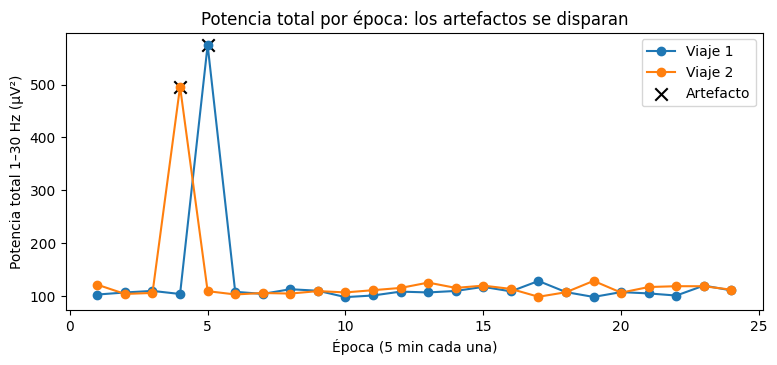

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for v, g in total.groupby(level="viaje"):
    ax.plot(g.index.get_level_values("epoca"), g.values, "o-", label=f"Viaje {v}")
ax.scatter([e for _, e in z10[z10].index], total[z10].values, marker="x", color="k", s=80, label="Artefacto")
ax.set_xlabel("Época (5 min cada una)"); ax.set_ylabel("Potencia total 1–30 Hz (µV²)")
ax.set_title("Potencia total por época: los artefactos se disparan"); ax.legend(); plt.show()

## 5. Potencia de cada banda: Simpson contra trapecio
$P=\int_{f_1}^{f_2}S(f)\,df$ en µV². **Validación obligatoria:** para $S(f)=f^2$ entre 4 y 8 Hz, $\int_4^8 f^2\,df=448/3$ y Simpson es exacto.

In [7]:
f = np.arange(4.0, 9.0)
print("Exacto 448/3 =", 448 / 3)
print("Simpson      =", modelo.simpson(f, f**2))
print("Trapecio     =", modelo.trapecio(f, f**2), "(sobreestima: f² es convexa)")

Exacto 448/3 = 149.33333333333334
Simpson      = 149.33333333333331
Trapecio     = 150.0 (sobreestima: f² es convexa)


In [8]:
trap = modelo.potencias_por_epoca(datos.ancha, params, "trapecio")
simp = datos.potencias
comp = pd.DataFrame({
    "Simpson (µV², media)": simp.mean(),
    "Trapecio (µV², media)": trap.mean(),
    "Error relativo medio (%)": (100 * (simp - trap).abs() / simp).mean(),
    "Error relativo máx. (%)": (100 * (simp - trap).abs() / simp).max(),
})
# Contraste con scipy (solo para comparar) en una época
fr = datos.ancha.columns.to_numpy(float); S0 = datos.ancha.iloc[0].to_numpy()
print("Época 1 total: propio trapecio", round(modelo.trapecio(fr, S0), 3),
      "| scipy", round(integrate.trapezoid(S0, fr), 3))
comp

Época 1 total: propio trapecio 105.176 | scipy 105.176


,"Simpson (µV², media)","Trapecio (µV², media)",Error relativo medio (%),Error relativo máx. (%)
theta,28.634,28.776,1.194,3.079
alfa,23.993,23.913,1.640,4.686
beta,27.411,27.498,0.717,2.219
total,127.908,131.054,1.892,6.774


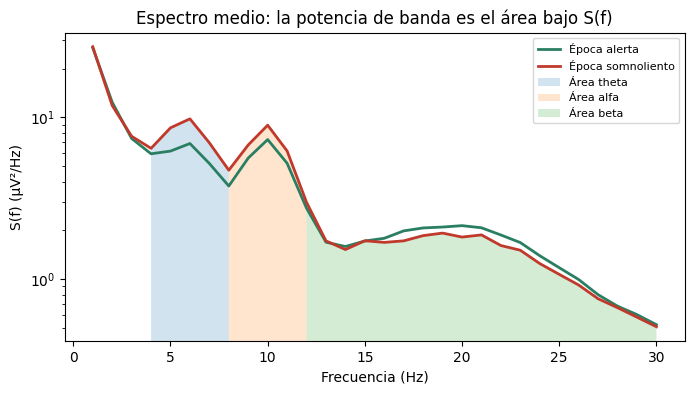

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ok = ~datos.artefacto
for nombre, clase, col in (("alerta", 0, "#2a7f62"), ("somnoliento", 1, "#c0392b")):
    S = datos.ancha.to_numpy()[ok & (datos.somnolencia == clase)].mean(axis=0)
    ax.plot(fr, S, color=col, lw=2, label=f"Época {nombre}")
    if clase == 1:
        for b, (a, c) in {"theta": (4, 8), "alfa": (8, 12), "beta": (12, 30)}.items():
            m = (fr >= a) & (fr <= c); ax.fill_between(fr[m], S[m], alpha=0.2, label=f"Área {b}")
ax.set_yscale("log"); ax.set_xlabel("Frecuencia (Hz)"); ax.set_ylabel("S(f) (µV²/Hz)")
ax.set_title("Espectro medio: la potencia de banda es el área bajo S(f)"); ax.legend(fontsize=8); plt.show()

## 6. Índice de somnolencia $I=(P_\theta+P_\alpha)/P_\beta$ y tiempo de reacción

Mediana de I en épocas alertas     : 1.585
Mediana de I en épocas somnolientas: 2.239
Correlación I vs tiempo de reacción, todas      : 0.262
Correlación I vs tiempo de reacción, sin artefactos: 0.69


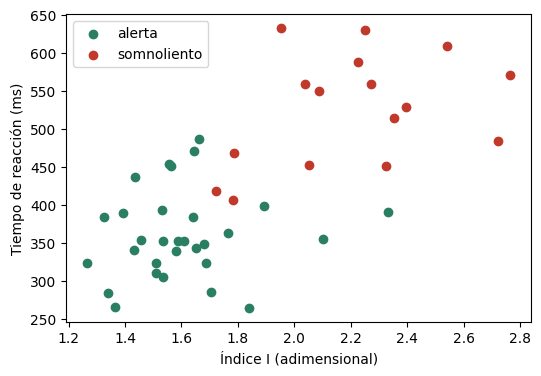

In [10]:
I = datos.indice; y = datos.somnolencia; ok = ~datos.artefacto
print("Mediana de I en épocas alertas     :", round(I[y == 0].median(), 3))
print("Mediana de I en épocas somnolientas:", round(I[y == 1].median(), 3))
print("Correlación I vs tiempo de reacción, todas      :", round(modelo.correlacion(I, datos.tiempo_reaccion), 3))
print("Correlación I vs tiempo de reacción, sin artefactos:", round(modelo.correlacion(I[ok], datos.tiempo_reaccion[ok]), 3))
fig, ax = plt.subplots(figsize=(6, 4))
for clase, nombre, col in ((0, "alerta", "#2a7f62"), (1, "somnoliento", "#c0392b")):
    k = ok & (y == clase); ax.scatter(I[k], datos.tiempo_reaccion[k], color=col, label=nombre)
ax.set_xlabel("Índice I (adimensional)"); ax.set_ylabel("Tiempo de reacción (ms)"); ax.legend(); plt.show()

## 7. Curva ROC y su área
Para cada umbral $c$ suena la alarma si $I\ge c$. Con TPR (sensibilidad) y FPR (1 − especificidad) se obtiene la ROC, y $AUC=\int_0^1 TPR\,d(FPR)$ se calcula con la **regla del trapecio**, con y sin artefactos. El AUC es la probabilidad de que una época somnolienta tenga un índice mayor que una alerta.

AUC con artefactos (n=48): 0.8887
AUC sin artefactos (n=46): 0.9479


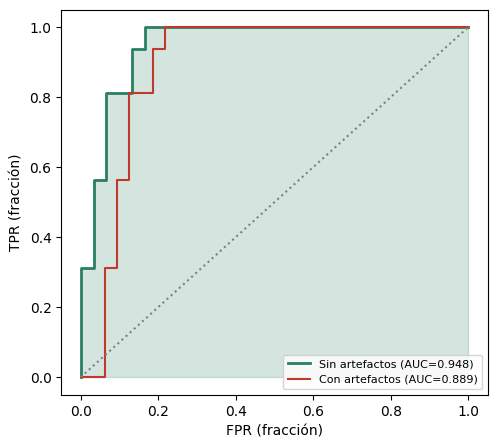

In [11]:
roc_con = modelo.curva_roc(I.to_numpy(), y)
roc_sin = modelo.curva_roc(I.to_numpy()[ok], y[ok])
print(f"AUC con artefactos (n={len(y)}): {roc_con.auc:.4f}")
print(f"AUC sin artefactos (n={ok.sum()}): {roc_sin.auc:.4f}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.fill_between(roc_sin.fpr, roc_sin.tpr, step="post", alpha=0.2, color="#2a7f62")
ax.step(roc_sin.fpr, roc_sin.tpr, where="post", color="#2a7f62", lw=2, label=f"Sin artefactos (AUC={roc_sin.auc:.3f})")
ax.step(roc_con.fpr, roc_con.tpr, where="post", color="#c0392b", label=f"Con artefactos (AUC={roc_con.auc:.3f})")
ax.plot([0, 1], [0, 1], ":", color="gray"); ax.set_xlabel("FPR (fracción)"); ax.set_ylabel("TPR (fracción)")
ax.legend(loc="lower right", fontsize=8); plt.show()

## 8. Umbral recomendado
Entre los umbrales con sensibilidad ≥ 90 % se elige el de menor costo: $\text{costo}=8\cdot FN + 1\cdot FP$ (valores de la hoja `Parametros`). Las falsas alarmas por hora se calculan sobre las horas de conducción alerta.

In [12]:
r = modelo.elegir_umbral(roc_sin, params["sens_min"], params["costo_omision"], params["costo_falsa_alarma"])
fa_h = r.falsas_alarmas_por_hora(int((y[ok] == 0).sum()), params["duracion_epoca_min"])
print(f"Umbral c* = {r.umbral:.3f} | sensibilidad = {r.sensibilidad:.1%} | especificidad = {r.especificidad:.1%}")
print(f"Costo = {r.costo:.0f} | falsas alarmas por hora = {fa_h:.2f}")
r.matriz_confusion()

Umbral c* = 1.724 | sensibilidad = 100.0% | especificidad = 83.3%
Costo = 5 | falsas alarmas por hora = 2.00


,sin alarma,con alarma
alerta,25,5
somnoliento,0,16


## 9. Escenarios y sensibilidad
Se comparan tres escenarios factibles y se estudia cuánto cambia el umbral al variar los costos.

In [13]:
tabla = esc.comparar_escenarios(datos)
tabla.set_index("escenario").T

escenario,Base (Parametros),Chofer prioritario (falsa alarma x10),Equipo sin filtro de artefactos
epocas_usadas,46.000,46.000,48.000
AUC,0.948,0.948,0.889
umbral,1.724,1.781,1.724
sensibilidad,1.000,0.938,1.000
especificidad,0.833,0.867,0.781
omisiones,0.000,1.000,0.000
falsas_alarmas,5.000,4.000,7.000
costo,5.000,48.000,7.000
falsas_alarmas_por_hora,2.000,1.600,2.625


In [14]:
barrido = esc.barrido_sensibilidad(datos, np.array([0.5, 1, 2, 4, 8, 16, 32]), np.array([0.8, 0.9, 0.95, 1.0]))
barrido.pivot(index="razon_omision_falsa_alarma", columns="sens_min", values="umbral")

sens_min,0.800,0.900,0.950,1.000
razon_omision_falsa_alarma,,,,
0.500,1.954,1.781,1.724,1.724
1.000,1.954,1.781,1.724,1.724
2.000,1.724,1.724,1.724,1.724
4.000,1.724,1.724,1.724,1.724
8.000,1.724,1.724,1.724,1.724
16.000,1.724,1.724,1.724,1.724
32.000,1.724,1.724,1.724,1.724


## 10. Verificación analítica
Se ajusta $S(f)\approx A f^{b}$ (mínimos cuadrados en escala log-log) al espectro medio de épocas alertas y se integra **analíticamente**:
$$\int_{f_1}^{f_2} A f^{b}\,df=\frac{A}{b+1}\left(f_2^{\,b+1}-f_1^{\,b+1}\right).$$
Se compara con Simpson sobre los datos.

In [15]:
S = datos.ancha.to_numpy()[ok & (y == 0)].mean(axis=0)
A, b = modelo.ajustar_ley_potencia(fr, S)
print(f"Ajuste: S(f) = {A:.2f} · f^{b:.3f}")
filas = []
for banda, (a, c) in {"theta": (4, 8), "alfa": (8, 12), "beta": (12, 30)}.items():
    ana = modelo.integral_ley_potencia(A, b, a, c); num = modelo.potencia_banda(S, fr, a, c, "simpson")
    filas.append({"banda": banda, "analítica (µV²)": ana, "Simpson (µV²)": num,
                  "error relativo (%)": 100 * modelo.error_relativo(ana, num)})
pd.DataFrame(filas)

Ajuste: S(f) = 32.14 · f^-1.016


,banda,analítica (µV²),Simpson (µV²),error relativo (%)
0,theta,21.662,22.938,5.564
1,alfa,12.560,21.386,41.273
2,beta,28.082,27.804,1.000


## 11. Conclusiones y limitaciones
- **Recomendación:** umbral $c\approx 1{,}72$ con filtro de artefactos: sensibilidad 100 %, especificidad ≈ 83 %, AUC ≈ 0,95 y ≈ 2 falsas alarmas por hora de conducción alerta.
- **Robustez:** el umbral no cambia si el costo de una omisión es entre 2 y 32 veces el de una falsa alarma. Solo sube (≈ 1,78) si ambos errores se consideran casi igual de graves.
- **Filtro de artefactos:** sin él, el AUC baja a ≈ 0,89 y las falsas alarmas suben a ≈ 2,6 por hora.
- **La ley de potencias** funciona en theta y beta, pero falla en alfa (pico alrededor de 10 Hz), por eso la integral numérica es la fuente principal.
- **Limitaciones:** solo 46 épocas (16 somnolientas) y 2 viajes simulados; la sensibilidad de 100 % tiene mucha incertidumbre. Antes de usarlo en buses reales hay que validar con más choferes y rutas.